# 14. HD maps

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/14_hdmap.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/14_hdmap.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-14.svg" alt="duckOSM notebook manual, chapter 14: HD maps" width="100%">

| **You learn** | what a lane map is; the lanes of GMNS; the road surfaces of lanes and junctions; a CommonRoad map and how commonroad-io reads it; a Lanelet2 map and how the `lanelet2` library reads it; the lane graph and a route from lane to lane; an OpenDRIVE file with and without junctions |
|---|---|
| **Time** | about 3 minutes |
| **Extras** | `duckosm[sim,hdmap]` (the install cell installs them) |
| **Next** | [15. Graph machine learning](15_ml.md): the road graph for networkx, rustworkx and PyTorch Geometric |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
# roadstyle (the maps) also comes from its nightly wheel, so the newest roadstyle parts work with no roadstyle release.
import importlib.util, json, os, urllib.request
def nightly_wheel(repo="Khoshkhah/duckOSM", name=".whl"):        # the address of the newest nightly wheel of a repository
    release = json.load(urllib.request.urlopen(f"https://api.github.com/repos/{repo}/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if name in a["name"] and a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[sim,hdmap] @ {nightly_wheel()}" lanelet2
    %pip install -q --force-reinstall --no-deps "roadstyle @ {nightly_wheel('Khoshkhah/roadstyle', 'manylinux')}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## What an HD map is

A road network of duckOSM has one edge for each direction of a road. That is enough to find a route or to draw a map.
An automated vehicle and a driving simulator need more: each **lane** of the road, its width and its borders, and
which lane continues into which lane through a junction. A map with these data is an **HD map** (a high-definition
map), or a lane map.

The lane maps of this chapter have the same parts with different names:

| Part | What it is | CommonRoad | Lanelet2 | OpenDRIVE |
|---|---|---|---|---|
| a lane | one lane of one road, with a left and a right border | a lanelet | a lanelet | a lane of a `road` |
| a lane connector | the path of a vehicle through a junction, from one lane to the next | a lanelet | (not made) | a connecting road |
| a link | which lane comes next, and which lane is beside it | predecessor, successor, adjacent left and right | the shared end points | `predecessor`, `successor`, `junction` |
| the coordinates | | metres from the center of the area | latitude and longitude | metres in the UTM zone |

duckOSM makes the lanes in two steps. First, `to_gmns` writes the lanes, the lane connectors and the turns in a GMNS
database (chapter 13). Then each call of `duckosm.hdmap` reads that database and writes one lane map. OpenDRIVE is the
exception: it can also read the network file directly.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/hdmap-flow.svg" alt="The flow: the network, the GMNS lanes, then CommonRoad, Lanelet2, the lane graph and OpenDRIVE" width="100%">

The table lists the formats of this chapter, the tools that read them, and the call that writes each one.

| Format | Used by | The call |
|---|---|---|
| CommonRoad (`.xml`) | motion planning research, the CommonRoad benchmarks and tools (commonroad-io) | `duckosm.hdmap.to_commonroad` |
| Lanelet2 (OSM XML) | Autoware and the `lanelet2` library | `duckosm.hdmap.to_lanelet2` |
| the lane graph (a DuckDB table) | a route that says which lane to be in | `duckosm.hdmap.lane_graph`, `duckosm.hdmap.route_lanes` |
| ASAM OpenDRIVE (`.xodr`) | driving simulators (CARLA, esmini) and microsimulators | `net.to_opendrive`, `duckosm.hdmap.to_opendrive` |

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The lanes come from OSM, not from a survey. Each lane map keeps the `edge_id` of its road, so a lanelet joins back to the network and to your own data. The borders are correct to about 1 m, not to 1 cm.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Lanelet2, the lane graph and OpenDRIVE are experimental in duckOSM. The sections below show what each output has today and what it does not have.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The lane maps use the driving network.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                                                         # the card

Network('monaco.duckdb', 39.6 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

The progress lines name the cut and the build. The card shows the driving network:
the edges, the nodes and the length.

## The lanes: `to_gmns`

`net.driving.to_gmns(path)` writes the GMNS network of the driving mode to a new DuckDB file. GMNS has one row for each
lane (`lane`), one for each lane connector through a junction (`lane_connector`), and one for each legal turn
(`movement`). SUMO's netconvert finds which lane goes to which lane, so this call needs the `sim` extra. Chapter 13
tells more about GMNS. This chapter uses only its lanes.

In [3]:
gmns = net.driving.to_gmns("out/gmns.duckdb")         # the lanes and the lane connectors (GMNS)
gmns["modes"]                                         # the rows of the GMNS tables

GMNS out/gmns.duckdb: done in 24.4 s

{'driving': {'node': 1772,
  'link': 2858,
  'lane': 3318,
  'movement': 3755,
  'signal_controller': 1,
  'curb_seg': 0}}

The driving network of Monaco has 2858 links and 3318 lanes: most roads have one
lane in each direction, and some have two or three. The 3755 movements are the legal turns from one link to another.

### Look at the lanes

The GMNS file is a DuckDB file, so you can read it with `duckdb`. A `lane_id` is `<edge_id>_<lane number>`. Lane 1 is
the leftmost lane in the direction of travel. `width` is in metres (3.25 m when OSM does not give it), and
`allowed_uses` says who can use the lane.

In [4]:
import duckdb                                                             # to read the GMNS file

with duckdb.connect("out/gmns.duckdb", read_only=True) as con:           # close the file after the cell
    print(con.sql("SELECT count(*) AS lane_connectors FROM gmns_driving.lane_connector").fetchone())
    lanes = con.sql("""SELECT lane_id, link_id AS edge_id, lane_num, width, allowed_uses
                       FROM gmns_driving.lane ORDER BY lane_num DESC, lane_id LIMIT 5""").df()   # the roads with most lanes first
lanes

(4123,)


,lane_id,edge_id,lane_num,width,allowed_uses
0,117961209473327056_3,117961209473327056,3,3.25,bus
1,2310952989087966563_3,2310952989087966563,3,3.25,bus
2,2704056288975717867_3,2704056288975717867,3,3.25,bus
3,3188778506000426711_3,3188778506000426711,3,3.25,bus
4,3563032824957564822_3,3563032824957564822,3,3.25,bus


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The first line is the number of lane connectors: 4123 paths through the junctions. The table shows lane 3 of roads with three lanes. Here the rightmost lane is a bus lane (`allowed_uses` is `bus`). `edge_id` is the road of each lane, so a lane joins to `driving.edges`.

## The road surfaces: `surfaces`

A lane in GMNS is a line with a width. For a map, a GIS study or a simulator you often need the surface: the area of
the road that the lane covers. `duckosm.hdmap.surfaces(gmns_db)` gives the surfaces as two GeoDataFrames, in degrees:

| Result | One row for | The polygon | Columns |
|---|---|---|---|
| `lanes` | each lane | the lane line to the edge of the junction, with the width of the lane | `lane_id`, `edge_id`, `lane_num`, `width`, `allowed_uses` |
| `junctions` | each junction node | all the lane connectors of the node, each with its width, as one area | `node_id`, `connectors` |

`connectors` is the number of lane connectors through the junction: a simple measure of how complex the junction
is.

In [5]:
lanes, junctions = duckosm.hdmap.surfaces("out/gmns.duckdb")    # two GeoDataFrames (EPSG:4326)
len(lanes), len(junctions)

(3318, 1727)

In [6]:
junctions.sort_values("connectors", ascending=False).head(3)    # the junctions with the most lane connectors

,node_id,connectors,geometry
1081,3538613930,12,"MULTIPOLYGON (((7.43905 43.7467, 7.43903 43.74..."
463,1079750690,9,"POLYGON ((7.43052 43.74269, 7.43048 43.74269, ..."
221,25239346,9,"POLYGON ((7.42468 43.73882, 7.42468 43.73882, ..."


Monaco has 3,318 lane surfaces and 1,727 junction surfaces. The junction with the most turns has 12 lane
connectors, and the next two have 9. A junction polygon can be a `MULTIPOLYGON` when its connectors do not touch.

### How much land the roads use

The areas need metres, so the cell changes the coordinates to the UTM zone of Monaco first.

In [7]:
utm = lanes.estimate_utm_crs()                                  # the UTM zone of Monaco: metres
lanes_m, junctions_m = lanes.to_crs(utm), junctions.to_crs(utm)
round(lanes_m.area.sum()), round(junctions_m.area.sum())        # m² of lanes, m² of junctions

(273212, 51739)

The lanes cover 273,212 m² and the junctions 51,739 m². Together this is about 0.32 km², or 14 % of the
2.39 km² of Monaco. The junctions are 16 % of the road surface.

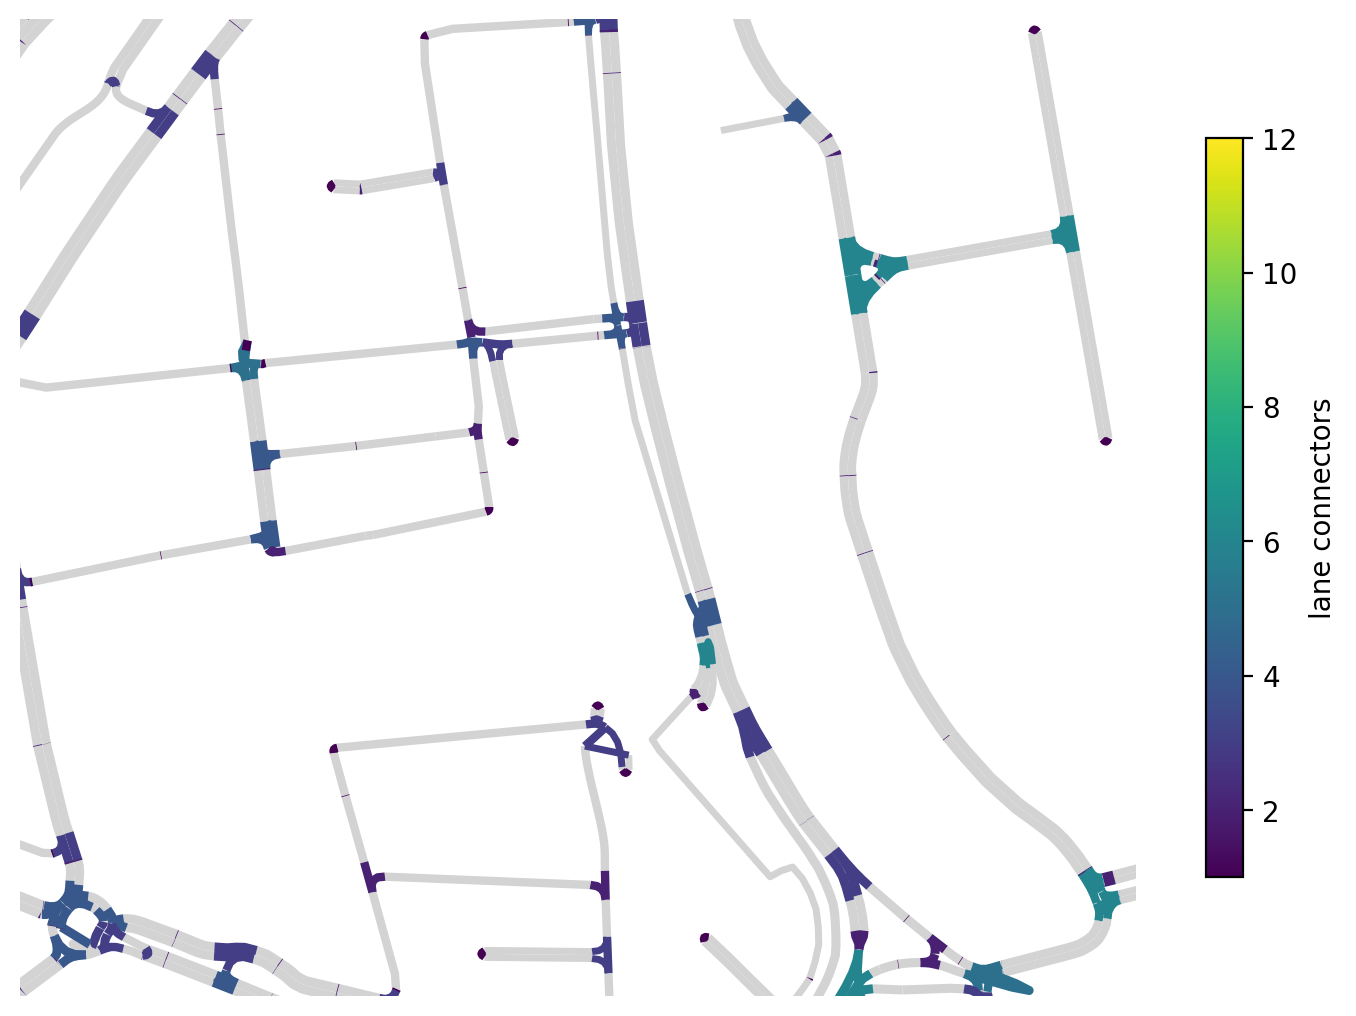

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))
lanes_m.plot(ax=ax, color="lightgray")                          # the lanes first, in light gray
junctions_m.plot(ax=ax, column="connectors", cmap="viridis", legend=True,
                 legend_kwds={"label": "lane connectors", "shrink": 0.6})    # the junctions by their connectors
ax.set_xlim(372650, 373050)                                     # a part of the center, in metres (UTM)
ax.set_ylim(4843350, 4843700)
ax.set_axis_off()

The picture shows a part of the center. The lanes are light gray. Each junction has the color of its number of
connectors: a junction with many turns is light, and a junction with one or two connectors is dark.

## CommonRoad

[CommonRoad](https://commonroad.in.tum.de) is a format and a set of tools for motion planning. A CommonRoad map is a
network of **lanelets**. `duckosm.hdmap.to_commonroad` reads the GMNS file and writes a CommonRoad scenario map:

- one lanelet for each lane, from the end of one junction to the start of the next (`geom_cut`).
- one lanelet for each lane connector, the path through the junction.
- for each lanelet, its predecessors, its successors, and the lane on its left and on its right in the same direction.
- the type of each lanelet: `urban`, `busLane` or `bicycleLane`, from the use of the lane.

The coordinates are metres east and north of the center of the area. The `location` of the file has the latitude and
the longitude of that center. The call needs commonroad-io (the `hdmap` extra).

| Argument | Default | What it does |
|---|---|---|
| `gmns_db` | (required) | the GMNS file of `to_gmns` |
| `path` | (required) | the CommonRoad file to write (`.xml`) |
| `mode` | `"driving"` | the mode of the GMNS file |
| `country_id`, `map_name` | `"ZAM"`, the file name | the scenario id: `<country_id>_<map_name>-1` |
| `author`, `affiliation` | `"duckOSM"`, `""` | the author data of the file |

In [9]:
cr = duckosm.hdmap.to_commonroad("out/gmns.duckdb", "out/monaco_commonroad.xml")    # the CommonRoad map
{k: v for k, v in cr.items() if k != "ids"}                                          # the numbers

{'path': PosixPath('out/monaco_commonroad.xml'),
 'lanelets': 7209,
 'lanes': 3318,
 'connectors': 4123,
 'dropped': 232}

The map has 7209 lanelets, from 3318 lanes and 4123 lane connectors. That is less
than 3318 + 4123 = 7441: a lane or a connector whose border cannot be drawn (for example a very short or sharp line)
has no lanelet.

### From a lanelet back to its road: `ids`

The result has `ids`, a DataFrame with one row for each lane and each connector: its `lanelet_id`, its GMNS id, and the
`edge_id` of its road. For a connector, the `edge_id` is the road that the connector comes from. Use `ids` to put a
result of CommonRoad (for example a planned path) back on the network, or your own data on the lanelets.

In [10]:
cr["ids"].head()    # each lanelet_id, its GMNS lane or connector, and its edge_id

,lanelet_id,gmns_id,edge_id
0,1,1003228148726728921_1,1003228148726728921
1,2,1014480835261600237_1,1014480835261600237
2,3,1015158544797938083_1,1015158544797938083
3,4,1016153299111353750_1,1016153299111353750
4,5,1016294143949642362_1,1016294143949642362


The first lanelets are lanes: their GMNS id is `<edge_id>_1`, lane 1 of the road.

### Read the map with commonroad-io

commonroad-io is the reference library of the format. It reads the file and makes a `LaneletNetwork`. Each lanelet has
its borders, its center line and its links.

In [11]:
from commonroad.common.file_reader import CommonRoadFileReader          # commonroad-io reads the file back

scenario, _ = CommonRoadFileReader("out/monaco_commonroad.xml").open()  # the scenario and its lanelets
lanelets = scenario.lanelet_network.lanelets
{"scenario": str(scenario.scenario_id), "lanelets": len(lanelets),
 "with a successor": sum(bool(x.successor) for x in lanelets),
 "with a lane on the right": sum(x.adj_right is not None for x in lanelets)}    # the links between the lanelets

{'scenario': 'ZAM_monacocommonroad-1',
 'lanelets': 7209,
 'with a successor': 6935,
 'with a lane on the right': 416}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Commonroad-io reads all 7209 lanelets. The scenario id comes from the defaults: the country `ZAM` (Zamunda, the test country of CommonRoad) and the file name without `_`. 6935 of them have a successor, so a vehicle can drive on from them. The others end at the edge of the area or at a dead end. 416 lanelets have a lane on their right in the same direction: these are the roads with two or more lanes.

### Draw the lanelets

Each lanelet has a polygon, its outline in metres. GeoPandas draws the polygons. The picture shows a part of the
center: the lanes are the long shapes, and the connectors are the curves through the junctions.

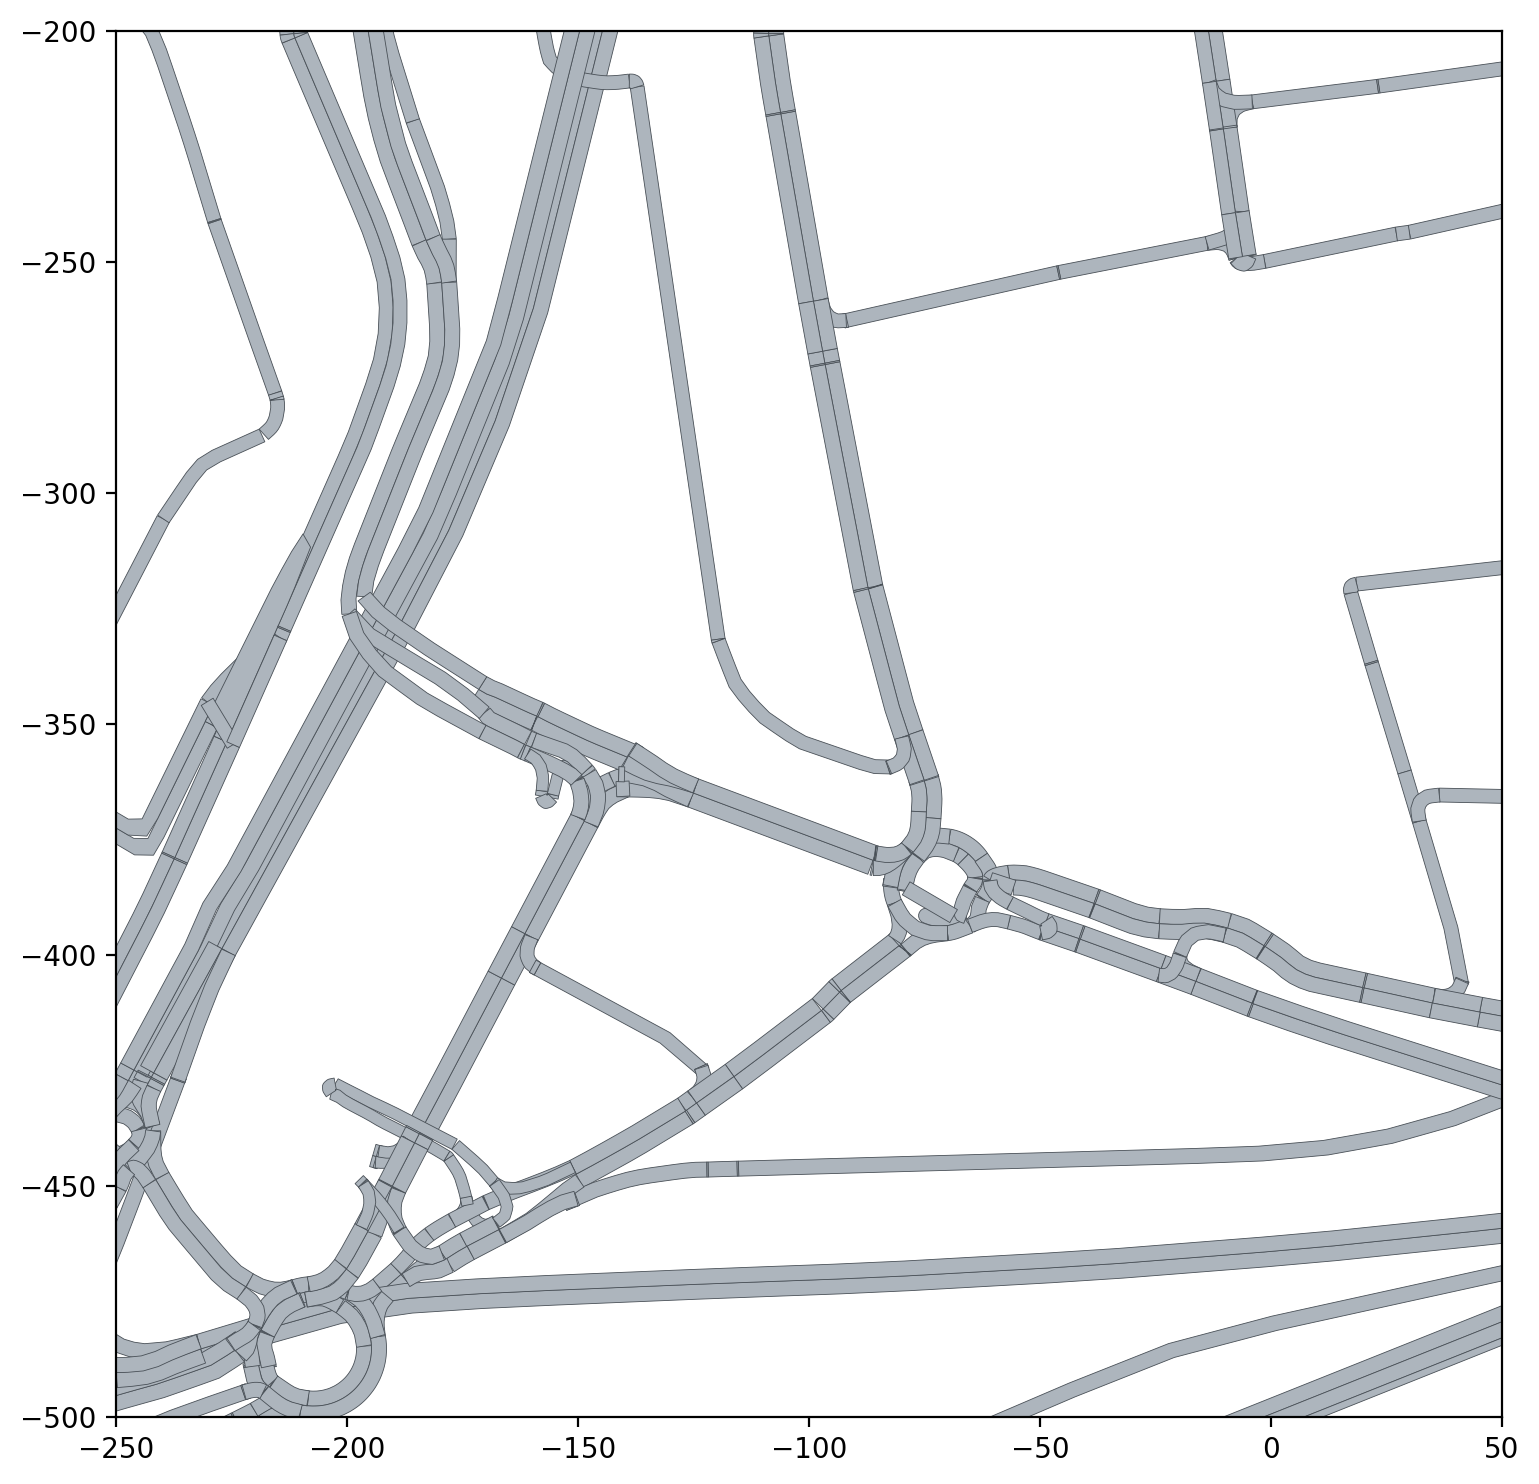

In [12]:
import geopandas as gpd
from shapely.geometry import Polygon                                     # to draw the lanelets

shapes = gpd.GeoSeries([Polygon(x.polygon.vertices) for x in lanelets])  # the outline of each lanelet, in metres
ax = shapes.plot(color="#adb5bd", edgecolor="#495057", linewidth=0.3, figsize=(9, 9))    # the lanelets
ax.set_xlim(-250, 50)                                                    # a part of the center, in metres
ax.set_ylim(-500, -200)
ax.set_aspect("equal")

The axes are metres from the center of Monaco. Each gray shape is one lanelet. Where
a road has two lanes, two lanelets lie side by side. In the junctions, short curved lanelets join the lanes: these are
the connectors, one for each lane that a lane can turn into.

### The scenario id and the author

`country_id` and `map_name` make the scenario id. CommonRoad uses the country to choose the traffic signs, so give the
country of the area as three letters. Monaco uses the French signs, so this map uses `FRA`. `author` and
`affiliation` go into the file as they are.

In [13]:
duckosm.hdmap.to_commonroad("out/gmns.duckdb", "out/monaco_fra.xml", country_id="FRA", map_name="Monaco",
                            author="My name", affiliation="My lab")             # the same map, other file data
scenario2, _ = CommonRoadFileReader("out/monaco_fra.xml").open()
str(scenario2.scenario_id), scenario2.author, scenario2.affiliation, scenario2.source

('FRA_Monaco-1', 'My name', 'My lab', 'duckOSM')

The scenario id is now `FRA_Monaco-1`. The author data are in the file, and the
source is `duckOSM`.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> `map_name` keeps only the letters and digits of the name, at most 32. CommonRoad uses `_` and `-` to split the parts of a scenario id, so a name with them gives a wrong id.

## Lanelet2

[Lanelet2](https://github.com/fzi-forschungszentrum-informatik/Lanelet2) is the lane map of Autoware. A Lanelet2 file
is OSM XML: nodes with a latitude and a longitude, ways for the borders, and one relation for each lanelet.
`duckosm.hdmap.to_lanelet2` writes one lanelet for each GMNS lane:

| Lanelet2 item | From the GMNS lane |
|---|---|
| left and right border | the center line of the lane, moved by half its width to each side |
| `subtype` | `road`, `bus_lane`, `bicycle_lane` or `walkway`, from the use of the lane |
| `speed_limit` | the speed of the road, in km/h |
| `location`, `one_way` | `urban`, `yes` |
| `duckosm:edge_id` | the `edge_id` of the road |

`snap_m` (default 0.01) joins two border points closer than this distance, in metres, into one node.

In [14]:
l2 = duckosm.hdmap.to_lanelet2("out/gmns.duckdb", "out/monaco_lanelet2.osm")    # the Lanelet2 map
l2                                                                                # the numbers

{'lanelets': 3318, 'ways': 6636, 'nodes': 86498}

The map has 3318 lanelets, one for each lane. Each lanelet has two borders, so the
file has 6636 ways. The 86498 nodes are the points of the borders.

### Read the map with `lanelet2`

The `lanelet2` library reads the file with a **projector**, which turns latitude and longitude into metres. The UTM
projector needs an origin near the area. `loadRobust` gives the map and the list of the faults that it found. A
routing graph then shows which lanelet follows which.

In [15]:
import lanelet2                                                           # the Lanelet2 library (pip install lanelet2)
from lanelet2.io import Origin
from lanelet2.projection import UtmProjector

projector = UtmProjector(Origin(43.735, 7.42))                            # metres around the center of Monaco
l2map, faults = lanelet2.io.loadRobust("out/monaco_lanelet2.osm", projector)    # the map and the faults of the file
rules = lanelet2.traffic_rules.create(lanelet2.traffic_rules.Locations.Germany,
                                      lanelet2.traffic_rules.Participants.Vehicle)  # the traffic rules of a car
graph = lanelet2.routing.RoutingGraph(l2map, rules)                       # which lanelet follows which
first = next(iter(l2map.laneletLayer))
{"lanelets": len(l2map.laneletLayer), "faults": len(faults),
 "with a next lanelet": sum(bool(graph.following(x)) for x in l2map.laneletLayer)}, dict(first.attributes)

({'lanelets': 3318, 'faults': 0, 'with a next lanelet': 732},
 {'duckosm:edge_id': '1271309973038490296',
  'location': 'urban',
  'one_way': 'yes',
  'speed_limit': '20',
  'subtype': 'bus_lane',
  'type': 'lanelet'})

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> `lanelet2` reads all 3318 lanelets with no fault. The attributes of the first lanelet are the tags of the table above, with its `duckosm:edge_id`. Only 732 lanelets have a next lanelet in the routing graph. Lanelet2 links two lanelets only when they share both end points of their borders. The lanes of duckOSM touch where the roads meet, but most do not share both points, and the Lanelet2 map has no connectors through the junctions.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Use the Lanelet2 map to look at the lanes and to read their tags. Do not use the `lanelet2` router on it yet. For a route from lane to lane, use the lane graph of the next section.

## The lane graph and a route from lane to lane

The lane graph is a network of lanes. A node is one whole lane, and an arc is one of two links:

| Link (`kind`) | Joins |
|---|---|
| a turn: `thru`, `left`, `right`, `uturn`, `merge`, `diverge` | a lane to each lane that it can turn into (legal turns only) |
| `lane_change` | a lane to the lane beside it, in the same direction |

The cost of an arc is the length in metres, plus a penalty for each turn and each lane change.

### Build the lane graph: `lane_graph`

`duckosm.hdmap.lane_graph(gmns_db)` writes the lane graph as the table `lane_driving.lane_edges` in the GMNS file, and
gives its numbers. `build_lane_graph` is the same call.

In [16]:
duckosm.hdmap.lane_graph("out/gmns.duckdb")             # the lane graph, into the GMNS file

{'lanes': 3318, 'lane_change': 836, 'turn': 4096, 'edges': 4932}

In [17]:
with duckdb.connect("out/gmns.duckdb", read_only=True) as con:          # the links of each kind
    kinds = con.sql("SELECT kind, count(*) AS links FROM lane_driving.lane_edges GROUP BY kind ORDER BY links DESC").df()
kinds

,kind,links
0,thru,2370
1,lane_change,836
2,right,639
3,left,479
4,uturn,219
5,diverge,197
6,merge,192


The graph has 3318 lanes and 4932 links: 4096 turns and 836 lane changes. Most
turns go straight on (`thru`, 2370). There are 219 U-turns, mostly at the ends of the roads with a turning place.

### A route: `route_lanes`

`duckosm.hdmap.route_lanes(gmns_db, from_lane, to_lane)` finds the cheapest path in the lane graph. `from_lane` and
`to_lane` are lane ids (`<edge_id>_<lane number>`) or `edge_id`s: an `edge_id` means lane 1 of that edge. The result
has the `lanes` of the route, its `cost`, its `maneuvers` and its `geometry` (WKT, in longitude and latitude). Here the
route goes from Boulevard du Jardin Exotique to Boulevard Princesse Charlotte.

In [18]:
ends = net.sql("""SELECT name, min(edge_id) AS edge_id FROM driving.edges
                  WHERE name IN ('Boulevard du Jardin Exotique', 'Boulevard Princesse Charlotte') AND lanes >= 2
                  GROUP BY name""").set_index("name").edge_id               # one edge with two lanes or more on each road
start, end = ends["Boulevard du Jardin Exotique"], ends["Boulevard Princesse Charlotte"]
route = duckosm.hdmap.route_lanes("out/gmns.duckdb", start, end)          # lane 1 of one edge to lane 1 of the other
{"lanes": len(route["lanes"]), "cost": round(route["cost"]), "first lanes": route["lanes"][:4]}

route_lanes[driving]: 27407470953641313_1 -> 117961209473327056_1: 40 lanes, cost 1408, 16 maneuvers


{'lanes': 40,
 'cost': 1408,
 'first lanes': ['27407470953641313_1',
  '6145912361430324039_1',
  '3490778726935261250_1',
  '3490778726935261250_2']}

In [19]:
from collections import Counter                                           # the maneuvers of the route

Counter(route["maneuvers"])

Counter({'right turn': 5,
         'left turn': 4,
         'merge': 4,
         'lane change': 2,
         'fork': 1})

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The route passes through 40 lanes, with a cost of 1408. Lanes 3 and 4 of the route are a lane change: the same `edge_id` with `_1` and then `_2`. The 16 maneuvers are the turns, merges, forks and lane changes on the way: 5 right turns, 4 left turns, 4 merges, 2 lane changes and 1 fork.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Where OSM has no `turn:lanes` (most roads), any lane can take any legal turn. So a route can turn from a lane that a real driver leaves first. Use it for planning, not for control of a vehicle.

## OpenDRIVE

[ASAM OpenDRIVE](https://www.asam.net/standards/detail/opendrive/) is the road format of driving simulators. duckOSM
writes OpenDRIVE 1.7. Each OpenDRIVE `road` is one direction of an edge, and its `id` is the `edge_id`. The reference
line is the edge line in metres, in the UTM zone of the area. Each driving lane is 3.25 m wide.

| Argument | Default | What it does |
|---|---|---|
| `net` | (required) | a network or a mode (`net.driving`). For `junctions=True`: the GMNS file |
| `out_path` | (required) | the `.xodr` file to write |
| `mode` | the mode of the view | the mode to write |
| `crs` | the UTM zone of the area | the coordinate system of the file, for example `"EPSG:32632"` |
| `junctions` | `False` | `True`: also a connecting road for each legal turn, and the junctions |

### The roads: `net.to_opendrive`

`net.driving.to_opendrive(path)` is the same as `duckosm.hdmap.to_opendrive(net.driving, path)`. Without junctions,
the roads do not link: you can look at them, but a vehicle cannot drive from road to road.

In [20]:
import xml.etree.ElementTree as ET                                       # to read the files back

odr = net.driving.to_opendrive("out/monaco.xodr")                        # the OpenDRIVE file, roads only
odr, len(ET.parse("out/monaco.xodr").findall("road"))                    # the numbers, and the roads in the file

OpenDRIVE out/monaco.xodr: done in 0.1 s

({'roads': 2840, 'crs': 'EPSG:32632'}, 2840)

The file has 2840 roads, one for each driving edge, in `EPSG:32632` (UTM zone
32 N, the zone of Monaco).

### The junctions: `junctions=True`

With `junctions=True`, each legal turn becomes a **connecting road**, a smooth curve through the junction, and the
connecting roads of one junction make a `junction`. The turns are the GMNS movements, so the source is the GMNS
file, not the network file.

In [21]:
odr_j = duckosm.hdmap.to_opendrive("out/gmns.duckdb", "out/monaco_junctions.xodr", mode="driving",
                                   junctions=True)                        # roads, connecting roads and junctions
root = ET.parse("out/monaco_junctions.xodr").getroot()
odr_j, len(root.findall("road")), len(root.findall("junction"))

({'roads': 2858,
  'connecting_roads': 1880,
  'junctions': 491,
  'crs': 'EPSG:32632'},
 4738,
 491)

The file has 2858 roads (the GMNS links), 1880 connecting roads and 491 junctions.
The roads and the connecting roads together are the 4738 `road` elements of the file.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A network file without the GMNS tables cannot give the junctions. The call then stops with `--junctions needs a GMNS db`. Make the GMNS file first and give its path.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> The heights of `duckosm elevation` go into the elevation profile of each road, but only without `junctions=True`.

## Try it yourself

**1.** Make a CommonRoad map of the lanes of Monaco with the country `FRA`, and count the lanelets of each type (`urban`, `busLane`, `bicycleLane`).

<details><summary>Show the answer</summary>

```python
from collections import Counter
duckosm.hdmap.to_commonroad("out/gmns.duckdb", "out/fra.xml", country_id="FRA")
sc, _ = CommonRoadFileReader("out/fra.xml").open()
Counter(next(iter(x.lanelet_type)).value for x in sc.lanelet_network.lanelets)
```
</details>

**2.** Find the lanelets of one road: use `cr["ids"]` to get the `lanelet_id`s of the `edge_id` `start` of the route section.

<details><summary>Show the answer</summary>

```python
cr["ids"][cr["ids"].edge_id == start]      # its lanes, and the connectors that leave it
```
</details>

**3.** Find a lane route in the other direction, from `end` to `start`, and compare its cost with the first route.

<details><summary>Show the answer</summary>

```python
back = duckosm.hdmap.route_lanes("out/gmns.duckdb", end, start)
round(back["cost"]), round(route["cost"]), len(back["lanes"])
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| HD map | a map with each lane of a road, its borders and its links: the map of an automated vehicle |
| lane | one lane of one road in one direction: a row of `gmns_driving.lane` |
| lane connector | the path of a vehicle through a junction, from one lane to the next |
| lanelet | a piece of lane with a left and a right border: the unit of CommonRoad and Lanelet2 |
| predecessor, successor | the lanelet before and the lanelet after a lanelet |
| adjacent lanelet | the lanelet on the left or on the right, in the same direction |
| projector | the rule that turns latitude and longitude into metres (Lanelet2) |
| lane graph | a network whose nodes are lanes and whose arcs are turns and lane changes |
| maneuver | one step of a lane route: a turn, a merge, a fork or a lane change |
| connecting road | an OpenDRIVE road through a junction, for one legal turn |

## Summary

| Call | Does |
|---|---|
| `net.driving.to_gmns(path)` | the lanes, the lane connectors and the turns, in a GMNS file (chapter 13) |
| `duckosm.hdmap.surfaces(gmns_db)` | the road surface of each lane and each junction, as two GeoDataFrames |
| `duckosm.hdmap.to_commonroad(gmns_db, path, ...)` | a CommonRoad map, with its numbers and `ids` (lanelet to `edge_id`) |
| `duckosm.hdmap.to_lanelet2(gmns_db, out_path, snap_m=0.01)` | a Lanelet2 map (OSM XML), one lanelet for each lane |
| `duckosm.hdmap.lane_graph(gmns_db)` (`build_lane_graph`) | the lane graph, as `lane_driving.lane_edges` in the GMNS file |
| `duckosm.hdmap.route_lanes(gmns_db, from_lane, to_lane)` | the cheapest route from lane to lane, with its maneuvers |
| `net.driving.to_opendrive(path)` | an OpenDRIVE file of the roads |
| `duckosm.hdmap.to_opendrive(src, out_path, crs=None, junctions=False)` | the same. With the GMNS file and `junctions=True`, also the junctions |

The reference: [duckosm.hdmap](../reference/sdk/hdmap.md), and the pages [OpenDRIVE](../exports/opendrive.md), [Lanelet2](../exports/lanelet2.md) and [Lane-level routing](../exports/lane-routing.md). **Next:** [15. Graph machine learning](15_ml.md), the road graph for networkx, rustworkx and PyTorch Geometric.